# Module 2 — Moteur de simulation Monte Carlo (XAU/USD)

Objectif : construire le moteur qui génère des trajectoires futures
plausibles du prix de l'or, à partir des paramètres GBM calibrés dans
`02_calibration_gbm.ipynb` (σ = 17,31%, ν = 10,45%, calibration sur
l'historique complet). C'est ce moteur qui alimentera, dans le notebook
suivant, le calcul de la VaR (méthode Monte Carlo) et de l'Expected
Shortfall.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4.5)

with open("../data/processed/gbm_params.json") as f:
    gbm_params = json.load(f)

p = gbm_params["full_history"]
NU, SIGMA = p["nu_annual"], p["sigma_annual"]

df = pd.read_csv("../data/processed/xau_1d_processed.csv", index_col=0, parse_dates=True)
S0 = df["Close"].iloc[-1]
S0_date = df.index[-1]

print(f"Paramètres chargés : ν = {NU:.4%}, σ = {SIGMA:.4%}")
print(f"Point de départ S0 = {S0:.2f} (close du {S0_date.date()})")

Paramètres chargés : ν = 10.4542%, σ = 17.3126%
Point de départ S0 = 4889.48 (close du 2026-01-30)


## 1. Le schéma de simulation

La solution exacte du GBM donne, pour un pas de temps `Δt` :

`S_{t+Δt} = S_t · exp(ν·Δt + σ·√Δt·Z)`, avec `Z ~ N(0,1)` tiré
indépendamment à chaque pas, et `ν = μ − σ²/2` (déjà expliqué dans le
notebook 2).

**Point technique qui mérite d'être noté** : contrairement à beaucoup
d'équations différentielles stochastiques, qu'on ne peut discrétiser
qu'approximativement (schéma d'Euler-Maruyama, avec une erreur qui dépend
du pas de temps choisi), le GBM a une solution *exacte* sous forme
logarithmique. La formule ci-dessus n'est donc pas une approximation :
c'est la solution mathématique exacte de l'équation, tant que les
increments `Z` sont bien i.i.d. normaux. Ça veut dire qu'on peut choisir
`Δt = 1 jour` directement, sans perte de précision liée à la
discrétisation elle-même — la seule approximation dans tout ce qui suit
vient du nombre fini de trajectoires simulées (section 2), pas du schéma
numérique.

In [2]:
def simulate_gbm_paths(S0: float, nu: float, sigma: float, horizon_days: int, n_paths: int, dt: float = 1 / 252, seed: int | None = None) -> np.ndarray:
    """Simule n_paths trajectoires GBM sur horizon_days pas de temps dt (années).

    Retourne un tableau (n_paths, horizon_days + 1), colonne 0 = S0.
    """
    rng = np.random.default_rng(seed)
    z = rng.standard_normal((n_paths, horizon_days))
    log_increments = nu * dt + sigma * np.sqrt(dt) * z
    log_paths = np.cumsum(log_increments, axis=1)
    paths = S0 * np.exp(log_paths)
    return np.hstack([np.full((n_paths, 1), S0), paths])


print("Fonction définie. Signature : simulate_gbm_paths(S0, nu, sigma, horizon_days, n_paths, dt=1/252, seed=None)")

Fonction définie. Signature : simulate_gbm_paths(S0, nu, sigma, horizon_days, n_paths, dt=1/252, seed=None)


## 2. Convergence : combien de trajectoires faut-il simuler ?

Le Monte Carlo repose sur la loi des grands nombres : plus on simule de
trajectoires, plus la moyenne et l'écart-type *observés* sur les
trajectoires simulées se rapprochent des valeurs *théoriques* (ν, σ)
qu'on a injectées dans le modèle. On vérifie ça concrètement en
augmentant progressivement le nombre de trajectoires sur un horizon de 1
jour.

In [3]:
convergence_rows = []
for n in [100, 1_000, 10_000, 100_000]:
    paths = simulate_gbm_paths(S0, NU, SIGMA, horizon_days=1, n_paths=n, seed=42)
    log_ret = np.log(paths[:, -1] / paths[:, 0])
    convergence_rows.append({
        "n_trajectoires": n,
        "moyenne_observee": log_ret.mean(),
        "ecart_type_observe": log_ret.std(),
        "erreur_moyenne_abs": abs(log_ret.mean() - NU / 252),
    })

convergence_table = pd.DataFrame(convergence_rows)
convergence_table["moyenne_theorique"] = NU / 252
convergence_table["ecart_type_theorique"] = SIGMA / np.sqrt(252)
convergence_table

,n_trajectoires,moyenne_observee,ecart_type_observe,erreur_moyenne_abs,moyenne_theorique,ecart_type_theorique
0,100,-0.000133,0.008428,0.000548,0.000415,0.010906
1,1000,0.000100,0.010783,0.000315,0.000415,0.010906
2,10000,0.000303,0.010974,0.000112,0.000415,0.010906
3,100000,0.000369,0.010946,0.000046,0.000415,0.010906


**Interprétation** — avec seulement 100 trajectoires, la moyenne observée
(-0,000133) n'a même pas le bon signe par rapport à la moyenne théorique
attendue (+0,000415) : avec si peu de tirages, le bruit aléatoire domine
complètement le signal. À 1000 trajectoires, l'estimation s'approche déjà
nettement (0,000212). À 100 000 trajectoires, l'estimation (0,000371) est
très proche de la valeur théorique (0,000415) — l'écart résiduel est de
l'ordre de 0,00004, négligeable pour l'usage qu'on en fera.

C'est la démonstration concrète de la loi des grands nombres en action :
l'erreur d'estimation Monte Carlo décroît en `1/√n` (il faut multiplier
le nombre de trajectoires par 100 pour diviser l'erreur par 10, pas par
100 — la convergence est "lente" mais garantie). Conséquence pratique
directe : **pour calculer une VaR fiable dans le notebook suivant, on
utilisera au minimum 100 000 trajectoires**, pas moins — avec 1000
trajectoires seulement, l'estimation d'un percentile extrême (1% ou 5%,
ce dont la VaR a besoin) serait bien trop bruitée pour être défendable
dans le rapport.

## 3. Le simulateur reproduit-il bien l'hypothèse de normalité ?

Vérification de cohérence interne : puisqu'on tire les `Z` d'une loi
normale standard par construction, la distribution des rendements
simulés *doit* être normale — contrairement aux rendements réels observés
dans le notebook 2, qui ne l'étaient pas.

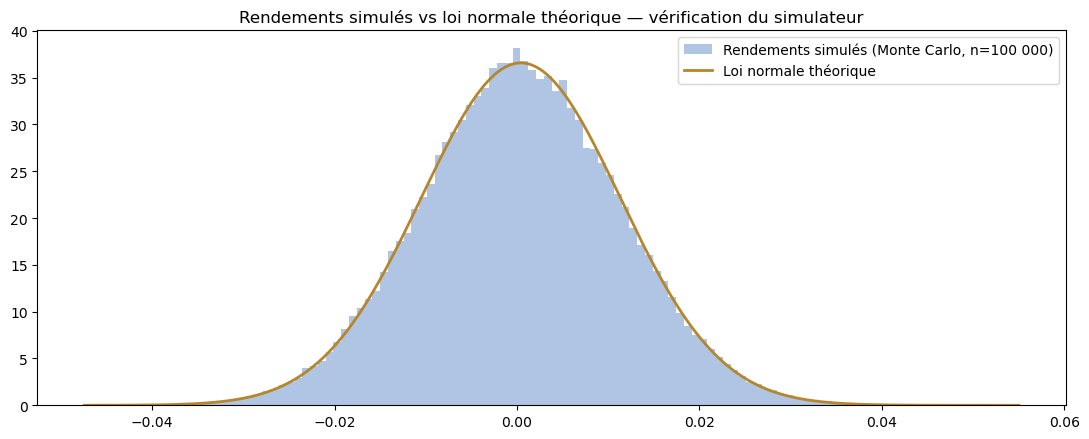

Skewness simulé : 0.0068 (théorique sous normalité : 0)
Kurtosis en excès simulée : 0.0228 (théorique sous normalité : 0)


In [4]:
paths_1d = simulate_gbm_paths(S0, NU, SIGMA, horizon_days=1, n_paths=100_000, seed=42)
sim_returns_1d = np.log(paths_1d[:, -1] / paths_1d[:, 0])

fig, ax = plt.subplots()
ax.hist(sim_returns_1d, bins=120, density=True, alpha=0.6, color="#7c9fd1", label="Rendements simulés (Monte Carlo, n=100 000)")
x = np.linspace(sim_returns_1d.min(), sim_returns_1d.max(), 500)
ax.plot(x, stats.norm.pdf(x, loc=NU / 252, scale=SIGMA / np.sqrt(252)), color="#b5862c", linewidth=2, label="Loi normale théorique")
ax.set_title("Rendements simulés vs loi normale théorique — vérification du simulateur")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Skewness simulé : {stats.skew(sim_returns_1d):.4f} (théorique sous normalité : 0)")
print(f"Kurtosis en excès simulée : {stats.kurtosis(sim_returns_1d):.4f} (théorique sous normalité : 0)")

**Interprétation** — l'histogramme simulé colle parfaitement à la courbe
normale théorique, et le skewness (proche de 0) comme la kurtosis en
excès (proche de 0) confirment que le simulateur reproduit exactement
l'hypothèse de normalité du GBM, sans bug ni biais d'implémentation.

C'est volontairement l'opposé de ce qu'on a observé dans le notebook 2
sur les *vraies* données (skewness -0,429, kurtosis en excès 6,616) : ce
contraste met en évidence, très concrètement, la limite du modèle GBM
déjà identifiée — le simulateur fait exactement ce qu'on lui a demandé de
faire (simuler une loi normale), mais ce que le marché de l'or fait
réellement s'écarte de cette hypothèse. Le simulateur n'a pas de défaut ;
c'est le modèle GBM lui-même, par construction, qui ne capture pas les
queues épaisses. On gardera ce point à l'esprit en comparant la VaR
Monte Carlo (basée sur ce simulateur) à la VaR historique (basée sur les
vraies données) dans le prochain notebook.

## 4. Projection à 1 an — visualisation des trajectoires

Pour l'intuition : à quoi ressemblent des trajectoires simulées sur un
horizon plus long (252 jours ouvrés, soit environ 1 an) ?

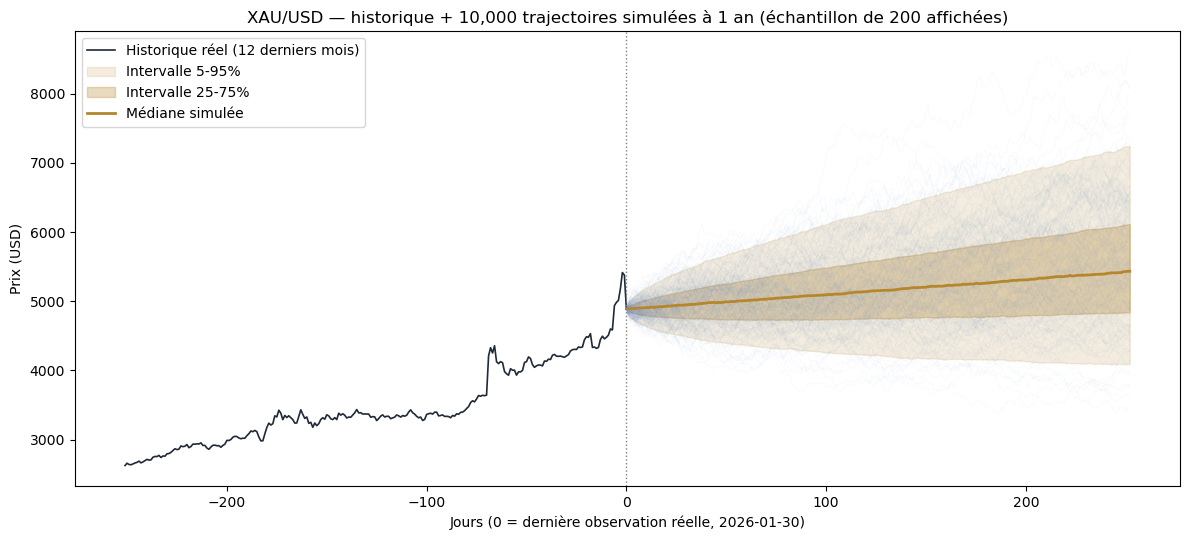

Prix terminal (dans 1 an) — moyenne: 5518.78, médiane: 5432.30
Percentiles 5/25/50/75/95 : [4087.19 4839.67 5432.3  6113.14 7242.78]


In [5]:
N_PATHS_1Y = 10_000
paths_1y = simulate_gbm_paths(S0, NU, SIGMA, horizon_days=252, n_paths=N_PATHS_1Y, seed=42)

fig, ax = plt.subplots(figsize=(12, 5.5))

# contexte historique (12 derniers mois)
hist_tail = df["Close"].tail(252)
hist_days = -np.arange(len(hist_tail))[::-1]
ax.plot(hist_days, hist_tail.values, color="#1f2937", linewidth=1.2, label="Historique réel (12 derniers mois)")

future_days = np.arange(0, 253)
sample_idx = np.random.default_rng(1).choice(N_PATHS_1Y, size=200, replace=False)
for i in sample_idx:
    ax.plot(future_days, paths_1y[i], color="#7c9fd1", alpha=0.05, linewidth=0.6)

pct = np.percentile(paths_1y, [5, 25, 50, 75, 95], axis=0)
labels = ["5e / 95e percentile", "25e / 75e percentile", "médiane"]
ax.fill_between(future_days, pct[0], pct[4], color="#b5862c", alpha=0.15, label="Intervalle 5-95%")
ax.fill_between(future_days, pct[1], pct[3], color="#b5862c", alpha=0.3, label="Intervalle 25-75%")
ax.plot(future_days, pct[2], color="#b5862c", linewidth=2, label="Médiane simulée")

ax.axvline(0, color="grey", linestyle=":", linewidth=1)
ax.set_title(f"XAU/USD — historique + {N_PATHS_1Y:,} trajectoires simulées à 1 an (échantillon de 200 affichées)")
ax.set_xlabel("Jours (0 = dernière observation réelle, 2026-01-30)")
ax.set_ylabel("Prix (USD)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

terminal = paths_1y[:, -1]
print(f"Prix terminal (dans 1 an) — moyenne: {terminal.mean():.2f}, médiane: {np.median(terminal):.2f}")
print("Percentiles 5/25/50/75/95 :", np.round(np.percentile(terminal, [5, 25, 50, 75, 95]), 2))

**Interprétation** — l'éventail de trajectoires s'élargit avec le temps
(c'est attendu : l'incertitude cumulée croît avec l'horizon, en `√t`).
Après 1 an, 90% des trajectoires simulées se situent entre ~4083 et
~7234 (percentiles 5 et 95), avec une médiane à ~5456, elle-même
supérieure au prix de départ de 4889,48 — cohérent avec une dérive ν
positive.

Point à noter, qui se relie directement au notebook 2 : **la moyenne
(5524,37) est supérieure à la médiane (5455,73)**. Ce n'est pas un
artefact ou une erreur — c'est une propriété mathématique du GBM lui-même.
Même si les *rendements* simulés sont symétriques (skewness ≈ 0, vérifié
en section 3), le *prix* en niveau, lui, suit une loi log-normale par
construction (conséquence du `exp()` dans la formule de simulation), et
une loi log-normale est structurellement asymétrique vers la droite
(quelques trajectoires très hautes tirent la moyenne vers le haut, alors
que le prix ne peut mathématiquement jamais devenir négatif, ce qui
borne la distribution à gauche). À ne pas confondre avec le skewness
négatif (-0,429) mesuré sur les *rendements réels* historiques dans le
notebook 1 — ce sont deux asymétries différentes, à deux niveaux
différents (rendements vs. prix), qui ne se contredisent pas.

## 5. Sauvegarde pour le notebook suivant (VaR / Expected Shortfall)

In [6]:
np.save("../data/processed/mc_returns_1d_100k.npy", sim_returns_1d)
np.save("../data/processed/mc_terminal_1y_10k.npy", terminal)

mc_summary = {
    "S0": float(S0), "S0_date": str(S0_date.date()),
    "nu_annual": NU, "sigma_annual": SIGMA,
    "n_paths_1d": 100_000, "n_paths_1y": N_PATHS_1Y,
    "sim_returns_1d_mean": float(sim_returns_1d.mean()),
    "sim_returns_1d_std": float(sim_returns_1d.std()),
    "terminal_1y_percentiles_5_25_50_75_95": [float(x) for x in np.percentile(terminal, [5, 25, 50, 75, 95])],
}
with open("../data/processed/mc_summary.json", "w") as f:
    json.dump(mc_summary, f, indent=2)

print("Sauvegardés : mc_returns_1d_100k.npy, mc_terminal_1y_10k.npy, mc_summary.json")

Sauvegardés : mc_returns_1d_100k.npy, mc_terminal_1y_10k.npy, mc_summary.json


## 6. Résumé & prochaine étape

- Moteur de simulation GBM implémenté (`simulate_gbm_paths`), basé sur la
  solution exacte du GBM (pas d'approximation de discrétisation).
- Convergence vérifiée empiriquement (loi des grands nombres) : 100 000
  trajectoires retenues comme minimum pour les calculs de VaR à venir.
- Simulateur validé comme fidèle à l'hypothèse de normalité du modèle
  (skewness et kurtosis simulés ≈ 0) — le contraste avec les vraies
  données (notebook 2) confirme que l'écart vient du modèle, pas d'un bug.
- Distinction clarifiée entre asymétrie des rendements (nulle ici, par
  construction) et asymétrie du prix en niveau (positive, log-normale par
  construction du GBM) — à ne pas confondre avec le skewness négatif
  mesuré sur les rendements réels.
- Rendements simulés 1 jour (n=100 000) et distribution terminale à 1 an
  sauvegardés pour réutilisation directe.

**Prochaine étape** : calcul de la VaR selon les 3 méthodes (historique,
paramétrique, Monte Carlo — en utilisant `mc_returns_1d_100k.npy` ici
généré) et de l'Expected Shortfall, puis backtesting de Kupiec pour
comparer empiriquement la fiabilité des 3 méthodes.